In [44]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
import kagglehub
import os
import glob
import matplotlib.pyplot as plt
from sklearn.utils import compute_class_weight

from keras.callbacks import ModelCheckpoint
from keras.layers import Dense, Flatten, Rescaling,BatchNormalization, Conv2D, MaxPooling2D
from keras.models import Sequential

from keras.callbacks import EarlyStopping
from keras.models import Sequential
from keras.layers import Dense, Input, Activation, Flatten,Dropout
from keras.utils import to_categorical

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [57]:
## read the data
path = kagglehub.dataset_download("jangedoo/utkface-new")
print(path)


Using Colab cache for faster access to the 'utkface-new' dataset.
/kaggle/input/utkface-new


In [58]:
print(os.listdir(path))

['UTKFace', 'utkface_aligned_cropped', 'crop_part1']


In [59]:
DATA_DIR = path + "/UTKFace"
files = os.listdir(DATA_DIR)
print(len(files))
print(files[:3])

23708
['26_0_2_20170104023102422.jpg.chip.jpg', '22_1_1_20170112233644761.jpg.chip.jpg', '21_1_3_20170105003215901.jpg.chip.jpg']


In [60]:
!mkdir -p ~/.kaggle
!cp "/content/kaggle (3).json" ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json
!pip install -q kaggle

cp: cannot stat '/content/kaggle (3).json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


## read the data

In [61]:
!kaggle datasets download -d jangedoo/utkface-new -p /content/data --unzip

Dataset URL: https://www.kaggle.com/datasets/jangedoo/utkface-new
License(s): copyright-authors
100% 331M/331M [00:21<00:00, 16.0MB/s]



In [62]:
!ls /content/data

crop_part1  UTKFace  utkface_aligned_cropped


In [63]:
folder = '/content/data/UTKFace'
len(os.listdir(folder))

23708

In [64]:
path = '/content/data/UTKFace/'
image_paths = glob.glob(path + '*.jpg')
print(len(image_paths))
image_paths[0]

23708


'/content/data/UTKFace/24_0_3_20170117150025331.jpg.chip.jpg'

In [65]:
from PIL import Image


/content/data/UTKFace/24_0_3_20170117150025331.jpg.chip.jpg


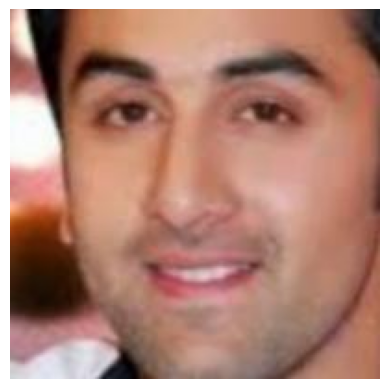

In [66]:
path = '/content/data/UTKFace/'
image_paths = glob.glob(path + '*.jpg')

print(image_paths[0])
plt.imshow(Image.open(image_paths[0]))
plt.axis("off")
plt.show()

In [55]:
DATA_DIR = path + "/UTKFace"

In [67]:
x= []
y= []

for f in files:
    img = tf.keras.utils.load_img(DATA_DIR + "/" + f, target_size=(64, 64))
    x.append(np.array(img) / 255.0)
    y.append(int(f.split("_")[0]))

x= np.array(x)
y= np.array(y)

In [68]:
print(x.shape, y.shape)

(23708, 64, 64, 3) (23708,)


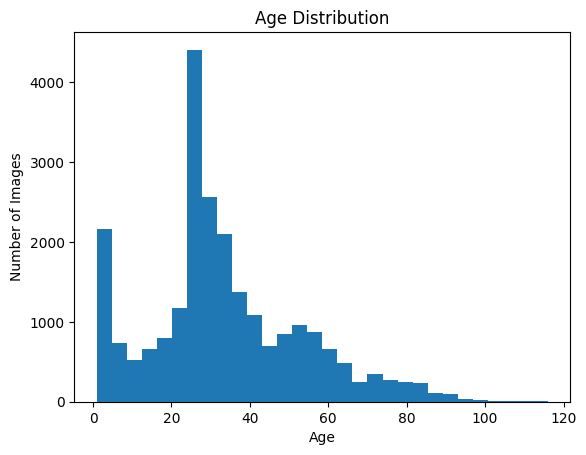

In [69]:
plt.hist(y, bins=30)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Images")
plt.show()

In [70]:
#image dimensions, color channels
print(x[0].shape)

(64, 64, 3)


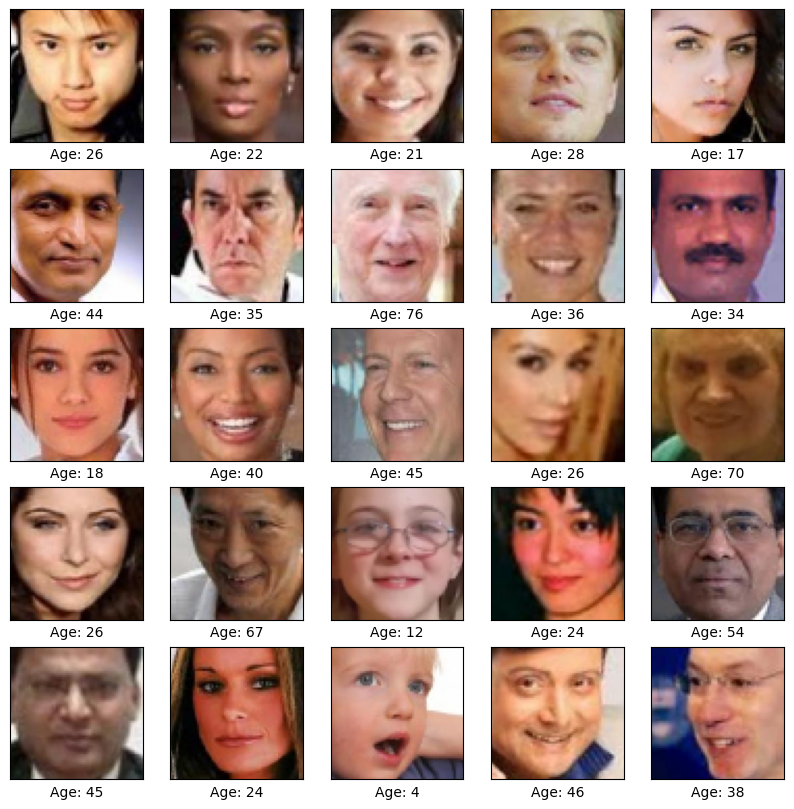

In [71]:
plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(x[i])
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.xlabel(f"Age: {int(y[i])}")

plt.show()

In [72]:
x_train_val, x_test, y_train_val, y_test= train_test_split(x, y, test_size=0.15, random_state=42)
x_train, x_val, y_train, y_val = train_test_split(x_train_val, y_train_val, test_size=0.15, random_state=42)

In [73]:
print(x_train.shape, x_val.shape, x_test.shape)

(17128, 64, 64, 3) (3023, 64, 64, 3) (3557, 64, 64, 3)


In [74]:
y_train[0:10]

array([26, 32, 26,  1, 29, 27, 80, 30, 59, 26])

## CNN  model

In [75]:
early_stoping=EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)

In [76]:
checkpoint_filepath = '/tmp/ckpt/checkpoint.model.keras'

model_checkpoint_callback = ModelCheckpoint(
    filepath=checkpoint_filepath,
    monitor='val_loss',
    mode='min',
    save_best_only=True)

In [77]:
from tensorflow.keras.utils import set_random_seed


In [78]:
set_random_seed(42)

cnn_model = Sequential([
                    Input(shape=(64, 64, 3)),
                    Conv2D(20, (3, 3),activation="relu"),
                    MaxPooling2D((2, 2)),

                    Conv2D(30, (3, 3),activation="relu"),
                    MaxPooling2D((2, 2)),

                    Conv2D(40, (3, 3), activation="relu"),

                    Flatten(), # converting 2D -> 1D

                    Dense(100, activation='relu'), # Hidden layer 1

                    Dense(100, activation='relu'), # Hidden layer 2

                    Dense(100, activation='relu'), # Hidden layer 3

                    Dense(1)
                    ])

In [79]:
cnn_model.compile(optimizer="adam", loss="mae", metrics=["mae"])

In [80]:
cnn_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 62, 62, 20)     │           560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 31, 31, 20)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 29, 29, 30)     │         5,430 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 14, 14, 30)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 12, 12, 40)     │        10,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 5760)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 100)            │       576,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 613,231 (2.34 MB)

 Trainable params: 613,231 (2.34 MB)

 Non-trainable params: 0 (0.00 B)

In [81]:
histor= cnn_model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=30,callbacks=[early_stoping ])

Epoch 1/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - loss: 14.5841 - mae: 14.5841 - val_loss: 12.0317 - val_mae: 12.0317
Epoch 2/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 10.1347 - mae: 10.1347 - val_loss: 9.0571 - val_mae: 9.0571
Epoch 3/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 8.5326 - mae: 8.5326 - val_loss: 8.1224 - val_mae: 8.1224
Epoch 4/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 7.8368 - mae: 7.8368 - val_loss: 8.3079 - val_mae: 8.3079
Epoch 5/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 7.3696 - mae: 7.3696 - val_loss: 7.4174 - val_mae: 7.4174
Epoch 6/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 7.0208 - mae: 7.0208 - val_loss: 7.4612 - val_mae: 7.4612
Epoch 7/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 6.7604 - mae: 6.7604 - val_loss: 7.0842 - val_mae: 7.0842
Epoch 8/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 6.4953 - mae: 6.4953 - val_loss: 6.9446 - val_mae: 6.9446
Epoch 9/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/s

In [82]:
hist=pd.DataFrame(histor.history)

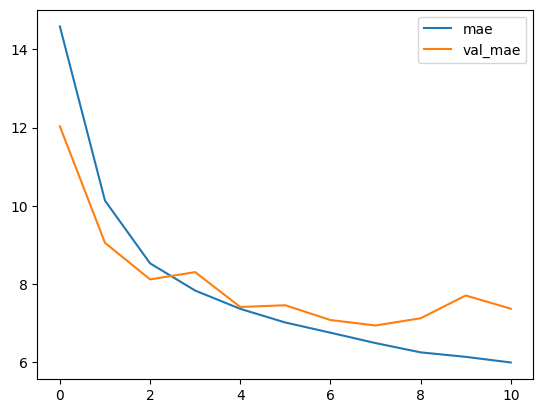

In [83]:
hist[["mae", "val_mae"]].plot();

In [85]:
test_loss, test_mae = cnn_model.evaluate(x_test, y_test)

112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 7.2442 - mae: 7.2442


In [86]:
# error analysis:

In [87]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay,mean_squared_error,mean_absolute_error,r2_score

In [88]:
y_pred = cnn_model.predict(x_test, verbose=0).flatten()

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Test MAE:", round(mae, 2))
print("Test MSE:", round(mse, 2))
print("Test RMSE:", round(rmse, 2))
print("Test R2 Score:", round(r2, 4))

Test MAE: 7.24
Test MSE: 110.05
Test RMSE: 10.49
Test R2 Score: 0.7182


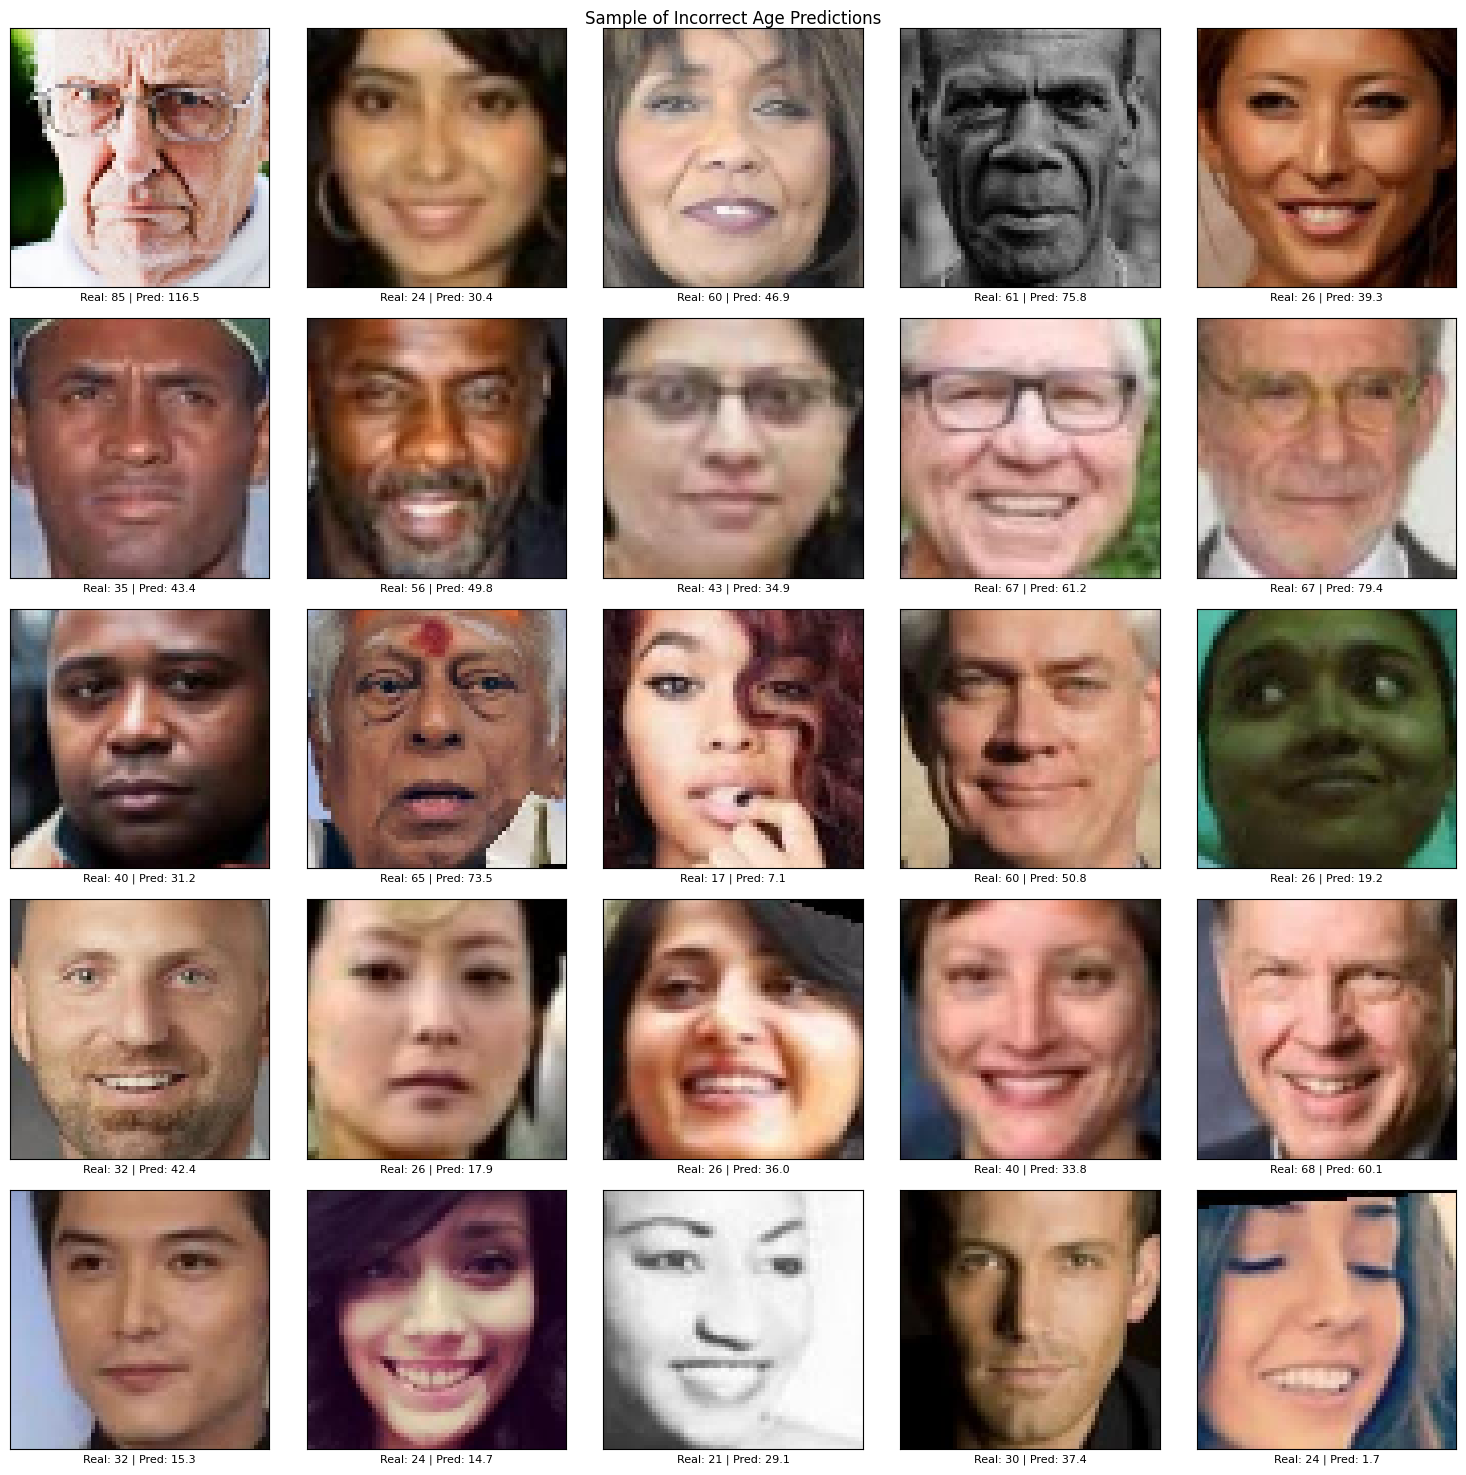

In [89]:
all_preds = cnn_model.predict(x_test, verbose=0).flatten()
errors = np.abs(y_test - all_preds)

wrong = np.where(errors > 5)[0]

plt.figure(figsize=(15, 15))

for i in range(min(25, len(wrong))):
    idx = wrong[i]

    plt.subplot(5, 5, i + 1)
    plt.imshow(x_test[idx])
    plt.xticks([])
    plt.yticks([])

    plt.xlabel(
        f"Real: {y_test[idx]} | Pred: {all_preds[idx]:.1f}",
        fontsize=8
    )

plt.suptitle("Sample of Incorrect Age Predictions")
plt.tight_layout()
plt.show()

In [90]:
cnn_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),loss="mae",metrics=["mae"])

In [91]:
history= cnn_model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=30,callbacks=[early_stoping,model_checkpoint_callback])

Epoch 1/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - loss: 5.5925 - mae: 5.5925 - val_loss: 6.6179 - val_mae: 6.6179
Epoch 2/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 5.4276 - mae: 5.4276 - val_loss: 6.5765 - val_mae: 6.5765
Epoch 3/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 5.3308 - mae: 5.3308 - val_loss: 6.5838 - val_mae: 6.5838
Epoch 4/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 5.2522 - mae: 5.2522 - val_loss: 6.5770 - val_mae: 6.5770
Epoch 5/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 5.1807 - mae: 5.1807 - val_loss: 6.5490 - val_mae: 6.5490
Epoch 6/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 5.1097 - mae: 5.1097 - val_loss: 6.5223 - val_mae: 6.5223
Epoch 7/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 5.0508 - mae: 5.0508 - val_loss: 6.5099 - val_mae: 6.5099
Epoch 8/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 4.9891 - mae: 4.9891 - val_loss: 6.5008 - val_mae: 6.5008
Epoch 9/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - 

In [92]:
history=pd.DataFrame(history.history)

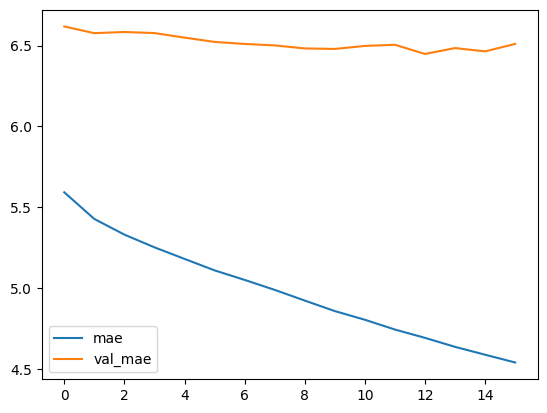

In [93]:
history[["mae", "val_mae"]].plot();

In [94]:
y_pred = cnn_model.predict(x_test, verbose=0).flatten()


In [95]:
mae= mean_absolute_error(y_test, y_pred)
mse= mean_squared_error(y_test, y_pred)
rmse= np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Test MAE:", mae)
print("Test MSE:", mse)
print("Test RMSE:", rmse)
print("R² Score:", r2)

Test MAE: 6.238931179046631
Test MSE: 83.46632385253906
Test RMSE: 9.135990578614837
R² Score: 0.7863116264343262


#  gradio


In [96]:
cnn_model.save("age_prediction_model.keras")

In [97]:
import gradio as gr


In [100]:
def predict_age(image):
    image = tf.image.resize(image, (64, 64))
    image = np.array(image, dtype=np.float32) / 255.0
    image = np.expand_dims(image, axis=0)

    prediction = cnn_model.predict(image, verbose=0)[0][0]

    return f"Predicted Age: {prediction:.0f} years"

In [101]:
demo = gr.Interface(
    fn=predict_age,
    inputs=gr.Image(type="numpy", image_mode="RGB",sources=["upload", "webcam"]),
    outputs=gr.Textbox(label="Predicted Age"),
    title="Age Prediction from Facial Images",
    description="Upload a facial image to predict the person's age."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


2026/10/28 10:57:46 [W] [service.go:132] login to server failed: dial tcp 44.237.78.176:7000: connect: connection refused


<IPython.core.display.Javascript object>